# Joint CACIB calibration: S&P 500, EURO STOXX 50 and Call vs Call

This notebook calibrates the two-dimensional Volterra Stein--Stein model in two stages:

1. the SPX and SX5E variance-swap term structures determine the two deterministic input curves $g_0^i$ exactly;
2. for each date and retained kernel family, the two marginal ATM-skew term structures and the Call vs Call term structure are calibrated jointly.

The retained joint specifications are shifted fractional / shifted fractional and two exponentials / two exponentials. The CVC observations of 29/01/2025 and 29/07/2025 are paired respectively with the marginal observations of 31/01/2025 and 31/07/2025.

## Model and joint objective

In the $d=n=2$ specialization of Example 1.1,

$$
G_0(t)=D(t)A(t)^{1/2},\qquad
D(t)=\operatorname{diag}\!\left(
\frac{g_0^1(t)}{\sqrt{\mathbb E[(Y_t^1)^2]}},
\frac{g_0^2(t)}{\sqrt{\mathbb E[(Y_t^2)^2]}}
\right).
$$

Consequently, the effective loading used by the Fourier discretization is $G_0(t)A(t)^{-1/2}=D(t)$. The joint pricing code therefore constructs `MM` with `compute_M_matrix_d2_n2` from the two marginal curves $g_0^i$.

Let $r_{\rm SPX}$ and $r_{\rm SX5E}$ be logarithmic errors on absolute ATM skews and let $r_{\rm CVC}$ be logarithmic CVC price errors. With $\lambda=1/3$, the residual vector passed to the optimizer is

$$
\begin{pmatrix}
\sqrt{\frac{1-\lambda}{2n_{\rm SPX}}}\,r_{\rm SPX}\\[2mm]
\sqrt{\frac{1-\lambda}{2n_{\rm SX5E}}}\,r_{\rm SX5E}\\[2mm]
\sqrt{\frac{\lambda}{n_{\rm CVC}}}\,r_{\rm CVC}
\end{pmatrix}.
$$

Thus each of the three market blocks contributes the same aggregate weight. The value of $\lambda$ is defined explicitly below so that alternative weightings can be tested without changing the pricing functions.

## Imports and paths

In [1]:
from functools import lru_cache
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.optimize import least_squares
from scipy.special import roots_laguerre

sns.set_style('darkgrid')

PROJECT_ROOT = next((
    root for root in [Path.cwd(), *Path.cwd().parents]
    if (root / 'src' / 'vss').is_dir()
    and (root / 'Market datas' / 'CACIB' / 'processed').is_dir()
), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Run this notebook from the project directory or one of its descendants.'
    )

SRC_PATH = PROJECT_ROOT / 'src'
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

PLOTS_DIRECTORY = (
    PROJECT_ROOT
    / 'Plots vss_joint_calibration_CACIB_SP500_SX5E_skew_vars_cvc_2y'
)
FULL_RESULTS_DIRECTORY = PLOTS_DIRECTORY / 'Full calibration results'
FULL_RESULTS_DIRECTORY.mkdir(parents=True, exist_ok=True)

from vss.calibration.variance_swap_g0 import (
    compute_piecewise_constant_g0_from_variance_swaps,
    evaluate_piecewise_constant_g0_on_grid,
    integrated_piecewise_constant_g0_squared,
)
from vss.fourier.call_vs_call_put_vs_put import (
    call_vs_call_put_vs_put_price_fourier,
)
from vss.fourier.flt_prefactor_free import (
    matrix_sqrt_psd,
    vss_fourier_laplace_det_prefactor_free,
)
from vss.fourier.parameters import (
    compute_V_matrix_for_fourier,
    compute_tilde_g_N0,
)
from vss.fourier.skew import skew_fourier
from vss.kernels.one_asset.shifted_fractional import (
    shifted_fractional_KK_SIG_d1_n1,
)
from vss.kernels.one_asset.sum_exponential import (
    sum_exponential_KK_SIG_d1_n1,
)
from vss.kernels.two_assets.SIG_from_SIG_integrals import (
    compute_SIG_matrix_d2_n2,
)
from vss.kernels.two_assets.shifted_fractional import (
    shifted_fractional_KK_SIG_d2_n2,
)
from vss.kernels.two_assets.sum_exponential import (
    sum_exponential_KK_SIG_d2_n2,
)
from vss.market_data.excel_extraction import extract_market_data_from_excel
from vss.market_data.skew import compute_market_skew
from vss.market_data.variance_swap_processing import clean_variance_swap_data
from vss.parameters import (
    compute_M_matrix,
    compute_M_matrix_d2_n2,
    compute_tilde_Gamma,
)


@lru_cache(maxsize=None)
def get_laguerre_rule(Q_laguerre):
    """Return and cache one Gauss--Laguerre rule."""

    return roots_laguerre(int(Q_laguerre))

## Market data

In [2]:
MARKET_DATA_DIRECTORY = PROJECT_ROOT / 'Market datas' / 'CACIB' / 'processed'

MAX_MARGINAL_MATURITY_YEARS = 2.0
MAX_CVC_MATURITY_YEARS = 2.5
MARGINAL_DATES = ('20250131', '20250731')
CVC_DATES = ('20250129', '20250729')
CVC_TO_MARGINAL_DATE = {
    '20250129': '20250131',
    '20250729': '20250731',
}

EXCEL_FILES = {
    f'SPX_{date}': MARKET_DATA_DIRECTORY / f'CACIB_SP500_iv_vars_vols_{date}.xlsx'
    for date in MARGINAL_DATES
}
EXCEL_FILES.update({
    f'SX5E_{date}': MARKET_DATA_DIRECTORY / f'CACIB_SX5E_iv_vars_{date}.xlsx'
    for date in MARGINAL_DATES
})

market_data = {}
for dataset, excel_file in EXCEL_FILES.items():
    extracted = extract_market_data_from_excel(excel_file)
    required = ('implied_volatility', 'variance_swaps')
    missing = [name for name in required if name not in extracted]
    if missing:
        raise ValueError(f'{dataset}: missing sheets {missing}')
    market_data[dataset] = {name: extracted[name] for name in required}

    implied_volatility = market_data[dataset]['implied_volatility']
    market_data[dataset]['implied_volatility'] = implied_volatility.loc[
        implied_volatility.index.to_numpy(dtype=float)
        <= MAX_MARGINAL_MATURITY_YEARS + 1e-12
    ].copy()
    for product in ('variance_swaps', 'volatility_swaps'):
        if product in market_data[dataset]:
            product_data = market_data[dataset][product]
            market_data[dataset][product] = product_data.loc[
                pd.to_numeric(product_data['maturity'], errors='raise')
                <= MAX_MARGINAL_MATURITY_YEARS + 1e-12
            ].copy().reset_index(drop=True)

CVC_FILES = {
    '20250129': MARKET_DATA_DIRECTORY / 'cvc_SP500_SX5E_20250129.xlsx',
    '20250729': MARKET_DATA_DIRECTORY / 'cvc_SP500_SX5E_20250729.xlsx',
}
cvc_market_data = {}
for cvc_date, cvc_file in CVC_FILES.items():
    data = pd.read_excel(cvc_file)
    expected_columns = ['maturity', 'call_vs_call_quote']
    if data.columns.tolist() != expected_columns:
        raise ValueError(
            f'{cvc_file.name}: expected {expected_columns}, got {data.columns.tolist()}'
        )
    data = data.loc[
        pd.to_numeric(data['maturity'], errors='raise')
        <= MAX_CVC_MATURITY_YEARS + 1e-12
    ].copy().reset_index(drop=True)
    if data.empty:
        raise ValueError(f'{cvc_file.name}: no observation within the selected horizon')
    values = data[expected_columns].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError(f'{cvc_file.name}: expected finite observations')
    if np.any(values <= 0.0) or np.any(np.diff(values[:, 0]) <= 0.0):
        raise ValueError(
            f'{cvc_file.name}: maturities and prices must be strictly positive'
        )
    cvc_market_data[cvc_date] = data.copy()

print('Marginal datasets:', ', '.join(market_data))
for cvc_date, data in cvc_market_data.items():
    print(f'\nCVC {cvc_date}')
    display(data)

Marginal datasets: SPX_20250131, SPX_20250731, SX5E_20250131, SX5E_20250731

CVC 20250129


,maturity,call_vs_call_quote
0,0.389041,0.002999
1,0.887671,0.004594
2,1.884932,0.006915



CVC 20250729


,maturity,call_vs_call_quote
0,0.391781,0.002499
1,1.389041,0.005495
2,2.386301,0.007173


# Variance-swap calibration

For variance-swap maturities $T_k$, the piecewise-constant curve $g_0$ is obtained from

$$
g_0(t)^2=
\frac{T_k\sigma_{\rm VS}(T_k)^2-T_{k-1}\sigma_{\rm VS}(T_{k-1})^2}
     {T_k-T_{k-1}},\qquad t\in[T_{k-1},T_k).
$$

This reconstructs every quoted total variance exactly. Beyond the final quoted maturity, the last calibrated value is extrapolated as a constant.

In [3]:
variance_swap_data = {}
g0_results = {}

for dataset, sheets in market_data.items():
    data = clean_variance_swap_data(sheets['variance_swaps'])
    variance_swap_data[dataset] = data
    maturities = data['maturity'].to_numpy(dtype=float)
    market_quotes = data['variance_swap_quote'].to_numpy(dtype=float)
    boundaries, g0_values = compute_piecewise_constant_g0_from_variance_swaps(
        maturities, market_quotes
    )
    integrated_variances = np.array([
        integrated_piecewise_constant_g0_squared(T, boundaries, g0_values)
        for T in maturities
    ])
    reconstructed = np.sqrt(integrated_variances / maturities)
    comparison = data.copy()
    comparison['reconstructed_variance_swap_quote'] = reconstructed
    comparison['error'] = reconstructed - market_quotes
    g0_results[dataset] = {
        'time_boundaries': boundaries,
        'G0_values': g0_values,
        'comparison': comparison,
    }
    print(
        f'{dataset}: maximum variance-swap reconstruction error = '
        f'{np.max(np.abs(comparison["error"])):.3e}'
    )

SPX_20250131: maximum variance-swap reconstruction error = 0.000e+00
SPX_20250731: maximum variance-swap reconstruction error = 5.551e-17
SX5E_20250131: maximum variance-swap reconstruction error = 0.000e+00
SX5E_20250731: maximum variance-swap reconstruction error = 2.776e-17


# ATM-skew targets

In [4]:
S0_MARGINAL = 1.0
Y0_MARGINAL = np.ones(1)
LOG_MONEYNESS = np.log(np.array([0.99, 1.01]))
SKEW_MONEYNESS = np.exp(LOG_MONEYNESS)

RHO_ONE = np.ones((1, 1))
R_W_ONE = np.ones((1, 1))
GAMMA_ONE = np.ones((1, 1))
TILDE_GAMMA_ONE = compute_tilde_Gamma(1, 1, GAMMA_ONE)

market_skew_maturities = {}
market_skews = {}
for dataset, sheets in market_data.items():
    surface = sheets['implied_volatility']
    maturities = surface.index.to_numpy(dtype=float)
    observed_moneyness = surface.columns.to_numpy(dtype=float)
    if surface.shape[1] != 2 or not np.allclose(
        np.log(observed_moneyness), LOG_MONEYNESS, rtol=0.0, atol=1e-12
    ):
        raise ValueError(f'{dataset}: expected only 99% and 101% moneyness')
    implied_volatilities = surface.to_numpy(dtype=float)
    market_skew_maturities[dataset] = maturities
    market_skews[dataset] = compute_market_skew(
        maturities, LOG_MONEYNESS, implied_volatilities
    )

# Numerical rules

In [5]:
def marginal_calibration_rule(T):
    """Return the marginal calibration pair (N, Q)."""

    if T <= 0.01:
        return 20, 128
    if T <= 0.10:
        return 30, 80
    if T <= 0.50:
        return 40, 60
    if T <= 1.0:
        return 50, 40
    return 80, 30


def marginal_validation_rule(T):
    """Return the marginal validation pair (N, Q)."""

    return marginal_calibration_rule(T)


def cvc_calibration_rule(T):
    """Return the CVC calibration pair (N, Q)."""

    if T <= 0.01:
        return 20, 32
    if T <= 0.10:
        return 30, 30
    if T <= 0.50:
        return 20, 30
    if T <= 1.0:
        return 25, 30
    return 30, 30


def cvc_validation_rule(T):
    """Return the CVC validation pair (N, Q)."""

    return cvc_calibration_rule(T)


print('Calibration and validation rules are currently identical.')
for cvc_date in CVC_DATES:
    rules = [
        cvc_calibration_rule(float(T))
        for T in cvc_market_data[cvc_date]['maturity']
    ]
    print(f'CVC {cvc_date}: {rules}')

Calibration and validation rules are currently identical.
CVC 20250129: [(20, 30), (25, 30), (30, 30)]
CVC 20250729: [(20, 30), (30, 30), (30, 30)]


# Joint calibration setup

The starting values are the parameters obtained from the corresponding cascade calibrations. Only one optimization is run from each starting point. The shifted-fractional bounds retain the date- and asset-specific bounds on $\nu$ used in the marginal calibrations. For the two-exponential specification, the disjoint bounds $\kappa_1\in[0.01,3]$ and $\kappa_2\in[3,50]$ enforce $\kappa_1\leq\kappa_2$ without permuting rates during optimization.

In [6]:
JOINT_LAMBDA = 1 / 3
SHIFTED_FRACTIONAL_DELTA = 1 / 52
CVC_ALPHA = np.array([0.25, 0.25])
CVC_S0 = np.ones(2)
CVC_STRIKE = np.array([1.0])

KERNEL_LABELS = {
    'shifted_fractional': 'Shifted fractional',
    'two_exp': 'Two exponentials',
}
KERNEL_COLORS = {
    'shifted_fractional': 'tab:orange',
    'two_exp': 'tab:red',
}

JOINT_CALIBRATION_CONFIGURATIONS = {
    ('20250129', 'shifted_fractional'): {
        'parameter_names': (
            'H_SPX', 'nu_SPX', 'c_SPX',
            'H_SX5E', 'nu_SX5E', 'c_SX5E', 'rho',
        ),
        'initial': np.array([
            0.14387114, 0.78224509, -0.999,
            0.08924456, 0.5, -0.84893586, 0.850285,
        ]),
        'lower': np.array([
            -0.49, 0.01, -0.999,
            -0.49, 0.01, -0.999, -0.999,
        ]),
        'upper': np.array([
            0.5, 0.8, -0.001,
            0.5, 0.5, -0.001, 0.999,
        ]),
    },
    ('20250729', 'shifted_fractional'): {
        'parameter_names': (
            'H_SPX', 'nu_SPX', 'c_SPX',
            'H_SX5E', 'nu_SX5E', 'c_SX5E', 'rho',
        ),
        'initial': np.array([
            0.10450227, 0.9226168, -0.999,
            -0.11622145, 0.49323834, -0.999, 0.897543,
        ]),
        'lower': np.array([
            -0.49, 0.01, -0.999,
            -0.49, 0.01, -0.999, -0.999,
        ]),
        'upper': np.array([
            0.5, 0.95, -0.001,
            0.5, 0.9, -0.001, 0.999,
        ]),
    },
    ('20250129', 'two_exp'): {
        'parameter_names': (
            'kappa_1_SPX', 'kappa_2_SPX', 'a_1_SPX', 'nu_SPX', 'c_SPX',
            'kappa_1_SX5E', 'kappa_2_SX5E', 'a_1_SX5E', 'nu_SX5E', 'c_SX5E',
            'rho',
        ),
        'initial': np.array([
            0.65743296, 24.88642883, 0.45570756, 2.3465546, -0.999,
            1.32106127, 32.38807409, 0.49687819, 1.43712293,
            -0.99349979, 0.843861,
        ]),
        'lower': np.array([
            0.01, 3.0, 0.0, 0.01, -0.999,
            0.01, 3.0, 0.0, 0.01, -0.999, -0.999,
        ]),
        'upper': np.array([
            3.0, 50.0, 1.0, 10.0, -0.001,
            3.0, 50.0, 1.0, 10.0, -0.001, 0.999,
        ]),
    },
    ('20250729', 'two_exp'): {
        'parameter_names': (
            'kappa_1_SPX', 'kappa_2_SPX', 'a_1_SPX', 'nu_SPX', 'c_SPX',
            'kappa_1_SX5E', 'kappa_2_SX5E', 'a_1_SX5E', 'nu_SX5E', 'c_SX5E',
            'rho',
        ),
        'initial': np.array([
            0.45406779, 19.96145495, 0.3760569, 2.93690044,
            -0.99899974,
            0.07793725, 20.27214231, 0.26363064, 3.10673805,
            -0.74868058, 0.937093,
        ]),
        'lower': np.array([
            0.01, 3.0, 0.0, 0.01, -0.999,
            0.01, 3.0, 0.0, 0.01, -0.999, -0.999,
        ]),
        'upper': np.array([
            3.0, 50.0, 1.0, 10.0, -0.001,
            3.0, 50.0, 1.0, 10.0, -0.001, 0.999,
        ]),
    },
}

for configuration in JOINT_CALIBRATION_CONFIGURATIONS.values():
    configuration['initial'] = configuration['initial'].astype(float)
    configuration['lower'] = configuration['lower'].astype(float)
    configuration['upper'] = configuration['upper'].astype(float)
    if not np.all(
        (configuration['lower'] <= configuration['initial'])
        & (configuration['initial'] <= configuration['upper'])
    ):
        raise ValueError('A joint-calibration starting point is outside its bounds')

## Parameter conversion and pricing functions

In [7]:
def split_joint_parameters(kernel_key, parameters):
    """Return SPX parameters, SX5E parameters and cross-asset rho."""

    parameters = np.asarray(parameters, dtype=float)
    if kernel_key == 'shifted_fractional':
        return parameters[:3], parameters[3:6], float(parameters[6])
    if kernel_key == 'two_exp':
        return parameters[:5], parameters[5:10], float(parameters[10])
    raise ValueError(f'Unknown kernel: {kernel_key}')


def marginal_specification(kernel_key, parameters):
    """Convert one marginal parameter vector to a common representation."""

    parameters = np.asarray(parameters, dtype=float)
    if kernel_key == 'shifted_fractional':
        H, nu, c = parameters
        return {
            'kind': 'fractional', 'H': H,
            'delta': SHIFTED_FRACTIONAL_DELTA, 'nu': nu, 'c': c,
        }
    if kernel_key == 'two_exp':
        kappa_1, kappa_2, a_1, nu, c = parameters
        return {
            'kind': 'exponential',
            'kappa': np.array([kappa_1, kappa_2]),
            'weights': np.array([a_1, 1.0 - a_1]),
            'nu': nu, 'c': c,
        }
    raise ValueError(f'Unknown kernel: {kernel_key}')


def build_one_asset_kernel(T, N, specification):
    """Build one marginal kernel and its nu-free covariance integrals."""

    if specification['kind'] == 'fractional':
        return shifted_fractional_KK_SIG_d1_n1(
            N=N, T=T, H=specification['H'], delta=specification['delta']
        )
    return sum_exponential_KK_SIG_d1_n1(
        N=N, T=T,
        kappa_array=specification['kappa'].reshape(1, -1),
        c_array=specification['weights'].reshape(1, -1),
    )


def build_two_asset_kernel(T, N, spx_specification, sx5e_specification):
    """Build the homogeneous two-asset kernel used by one joint calibration."""

    specifications = (spx_specification, sx5e_specification)
    kinds = tuple(specification['kind'] for specification in specifications)
    if kinds == ('fractional', 'fractional'):
        return shifted_fractional_KK_SIG_d2_n2(
            N=N, T=T,
            H_array=np.array([specification['H'] for specification in specifications]),
            delta_array=np.array([
                specification['delta'] for specification in specifications
            ]),
        )
    if kinds == ('exponential', 'exponential'):
        return sum_exponential_KK_SIG_d2_n2(
            N=N, T=T,
            kappa_array=np.vstack([
                specification['kappa'] for specification in specifications
            ]),
            c_array=np.vstack([
                specification['weights'] for specification in specifications
            ]),
        )
    raise ValueError(f'Unsupported kernel kinds: {kinds}')


@lru_cache(maxsize=None)
def g0_grid(dataset, T, N):
    """Evaluate one calibrated marginal g0 curve on a Fourier left grid."""

    result = g0_results[dataset]
    return evaluate_piecewise_constant_g0_on_grid(
        T, N, result['time_boundaries'], result['G0_values']
    )


def marginal_transform_values(dataset, T, N, nodes, specification):
    """Return marginal transform values for arbitrary Laguerre nodes."""

    KK, SIG_nu_free = build_one_asset_kernel(T, N, specification)
    nu_matrix = np.array([[specification['nu']]])
    SIG = np.kron(SIG_nu_free, nu_matrix @ nu_matrix.T)
    C_matrix = np.array([[specification['c']]])
    MM = compute_M_matrix(
        n=1, d=1, N=N, SIG=SIG, Gamma=GAMMA_ONE,
        tilde_Gamma=TILDE_GAMMA_ONE, rho=RHO_ONE,
        G0=g0_grid(dataset, T, N), Y0=Y0_MARGINAL,
    )
    V = compute_V_matrix_for_fourier(
        1, N, T, nu_matrix, R_W_ONE, KK, SIG, MM
    )
    sqrt_V = matrix_sqrt_psd(V)
    g_tilde = compute_tilde_g_N0(Y0_MARGINAL, 1, N, MM)
    u_array = (0.5 + 1j * nodes).reshape(-1, 1)
    w_array = np.zeros((len(nodes), 1, 1), dtype=complex)
    return vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, 1, 1, N, T, C_matrix,
        RHO_ONE, R_W_ONE, V, sqrt_V, g_tilde,
    )


def marginal_atm_skew(dataset, T, specification, rule_function):
    """Price one marginal ATM skew using the requested numerical rule."""

    N, Q_laguerre = rule_function(float(T))
    nodes, weights = get_laguerre_rule(Q_laguerre)
    transform_values = marginal_transform_values(
        dataset, float(T), N, nodes, specification
    )
    return skew_fourier(
        transform_values, S0_MARGINAL, float(T),
        LOG_MONEYNESS, nodes, weights,
    )


def marginal_skew_term_structure(dataset, specification, rule_function):
    """Return the complete model ATM-skew term structure."""

    return np.array([
        marginal_atm_skew(dataset, T, specification, rule_function)
        for T in market_skew_maturities[dataset]
    ])

In [8]:
GAMMA_TWO = np.array([
    [1.0, 0.0],
    [0.0, 0.0],
    [0.0, 0.0],
    [0.0, 1.0],
])
Y0_TWO = np.ones(2)


def cvc_price(
    cvc_date,
    T,
    spx_specification,
    sx5e_specification,
    rho_value,
    rule_function,
):
    """Return one Example 1.1 Call vs Call price."""

    marginal_date = CVC_TO_MARGINAL_DATE[cvc_date]
    spx_dataset = f'SPX_{marginal_date}'
    sx5e_dataset = f'SX5E_{marginal_date}'
    T = float(T)
    N, Q_laguerre = rule_function(T)
    nodes, weights = get_laguerre_rule(Q_laguerre)

    rho_matrix = np.array([[1.0, rho_value], [rho_value, 1.0]])
    nu_vector = np.array([
        spx_specification['nu'], sx5e_specification['nu']
    ])
    nu_matrix = np.diag(nu_vector)
    C_matrix = np.diag([
        spx_specification['c'], sx5e_specification['c']
    ])
    R_W = (
        C_matrix.T @ rho_matrix @ C_matrix
        + np.eye(2)
        - np.diag(np.diag(C_matrix.T @ C_matrix))
    )

    KK, SIG_integrals = build_two_asset_kernel(
        T, N, spx_specification, sx5e_specification
    )
    SIG = compute_SIG_matrix_d2_n2(SIG_integrals, nu_vector, R_W)
    marginal_g0 = np.column_stack([
        g0_grid(spx_dataset, T, N)[:, 0, 0],
        g0_grid(sx5e_dataset, T, N)[:, 0, 0],
    ])
    MM = compute_M_matrix_d2_n2(
        N=N, SIG=SIG, Gamma=GAMMA_TWO,
        marginal_G0=marginal_g0, Y0=Y0_TWO,
    )
    V = compute_V_matrix_for_fourier(
        2, N, T, nu_matrix, R_W, KK, SIG, MM
    )
    sqrt_V = matrix_sqrt_psd(V)
    g_tilde = compute_tilde_g_N0(Y0_TWO, 2, N, MM)

    x_1, x_2 = np.meshgrid(nodes, nodes, indexing='ij')
    joint_u_array = np.vstack([
        np.column_stack([
            CVC_ALPHA[0] - 1j * x_1.ravel(),
            CVC_ALPHA[1] - 1j * x_2.ravel(),
        ]),
        np.column_stack([
            CVC_ALPHA[0] - 1j * x_1.ravel(),
            CVC_ALPHA[1] + 1j * x_2.ravel(),
        ]),
    ])
    joint_w_array = np.zeros(
        (joint_u_array.shape[0], 2, 2), dtype=complex
    )
    joint_values = vss_fourier_laplace_det_prefactor_free(
        joint_u_array, joint_w_array, 2, 2, N, T,
        C_matrix, rho_matrix, R_W, V, sqrt_V, g_tilde,
    ).reshape(2, Q_laguerre, Q_laguerre)

    marginal_values = np.vstack([
        marginal_transform_values(
            spx_dataset, T, N, nodes, spx_specification
        ),
        marginal_transform_values(
            sx5e_dataset, T, N, nodes, sx5e_specification
        ),
    ])
    return call_vs_call_put_vs_put_price_fourier(
        joint_fourier_laplace_values=joint_values,
        marginal_fourier_laplace_values=marginal_values,
        S_0=CVC_S0,
        K_array=CVC_STRIKE,
        alpha=CVC_ALPHA,
        joint_sample_points=nodes,
        joint_weights=weights,
        marginal_sample_points=nodes,
        marginal_weights=weights,
        option_type='call_vs_call',
    )[0]


def cvc_term_structure(
    cvc_date,
    spx_specification,
    sx5e_specification,
    rho_value,
    rule_function,
):
    """Return all three CVC model prices for one date."""

    return np.array([
        cvc_price(
            cvc_date, T, spx_specification, sx5e_specification,
            rho_value, rule_function,
        )
        for T in cvc_market_data[cvc_date]['maturity'].to_numpy(dtype=float)
    ])

## Objective, optimizer and diagnostics

In [9]:
def logarithmic_absolute_residuals(model, market):
    """Return log absolute-value residuals after validating inputs."""

    model = np.asarray(model, dtype=float)
    market = np.asarray(market, dtype=float)
    if (
        not np.isfinite(model).all()
        or not np.isfinite(market).all()
        or np.any(np.abs(model) <= 0.0)
        or np.any(np.abs(market) <= 0.0)
    ):
        raise ValueError('Skew magnitudes must be finite and strictly positive')
    return np.log(np.abs(model)) - np.log(np.abs(market))


def logarithmic_positive_residuals(model, market):
    """Return logarithmic residuals for strictly positive prices."""

    model = np.asarray(model, dtype=float)
    market = np.asarray(market, dtype=float)
    if (
        not np.isfinite(model).all()
        or not np.isfinite(market).all()
        or np.any(model <= 0.0)
        or np.any(market <= 0.0)
    ):
        raise ValueError('CVC prices must be finite and strictly positive')
    return np.log(model) - np.log(market)


def evaluate_joint_model(cvc_date, kernel_key, parameters, rule_kind):
    """Evaluate the two marginal skews and CVC term structure."""

    marginal_date = CVC_TO_MARGINAL_DATE[cvc_date]
    spx_dataset = f'SPX_{marginal_date}'
    sx5e_dataset = f'SX5E_{marginal_date}'
    spx_parameters, sx5e_parameters, rho_value = split_joint_parameters(
        kernel_key, parameters
    )
    spx_specification = marginal_specification(kernel_key, spx_parameters)
    sx5e_specification = marginal_specification(kernel_key, sx5e_parameters)

    if rule_kind == 'calibration':
        marginal_rule = marginal_calibration_rule
        cvc_rule = cvc_calibration_rule
    elif rule_kind == 'validation':
        marginal_rule = marginal_validation_rule
        cvc_rule = cvc_validation_rule
    else:
        raise ValueError("rule_kind must be 'calibration' or 'validation'")

    return {
        'spx_skews': marginal_skew_term_structure(
            spx_dataset, spx_specification, marginal_rule
        ),
        'sx5e_skews': marginal_skew_term_structure(
            sx5e_dataset, sx5e_specification, marginal_rule
        ),
        'cvc_prices': cvc_term_structure(
            cvc_date, spx_specification, sx5e_specification,
            rho_value, cvc_rule,
        ),
    }


def joint_block_residuals(cvc_date, model_values):
    """Return the three unweighted log-residual blocks."""

    marginal_date = CVC_TO_MARGINAL_DATE[cvc_date]
    return {
        'SPX ATM skew': logarithmic_absolute_residuals(
            model_values['spx_skews'], market_skews[f'SPX_{marginal_date}']
        ),
        'SX5E ATM skew': logarithmic_absolute_residuals(
            model_values['sx5e_skews'], market_skews[f'SX5E_{marginal_date}']
        ),
        'CVC': logarithmic_positive_residuals(
            model_values['cvc_prices'],
            cvc_market_data[cvc_date]['call_vs_call_quote'].to_numpy(dtype=float),
        ),
    }


def weighted_joint_residuals(cvc_date, model_values, lambda_value=JOINT_LAMBDA):
    """Return the normalized residual vector supplied to least_squares."""

    blocks = joint_block_residuals(cvc_date, model_values)
    spx = blocks['SPX ATM skew']
    sx5e = blocks['SX5E ATM skew']
    cvc = blocks['CVC']
    return np.concatenate([
        np.sqrt((1.0 - lambda_value) / (2.0 * len(spx))) * spx,
        np.sqrt((1.0 - lambda_value) / (2.0 * len(sx5e))) * sx5e,
        np.sqrt(lambda_value / len(cvc)) * cvc,
    ])


def residual_summary(blocks, stage):
    """Return per-block log-error diagnostics."""

    rows = []
    for block_name, residuals in blocks.items():
        rows.append({
            'stage': stage,
            'block': block_name,
            'log_RMSE': np.sqrt(np.mean(residuals**2)),
            'maximum_absolute_log_error': np.max(np.abs(residuals)),
        })
    return rows


def calibrate_joint_model(cvc_date, kernel_key):
    """Run one joint marginal/CVC least-squares calibration."""

    configuration = JOINT_CALIBRATION_CONFIGURATIONS[(cvc_date, kernel_key)]
    initial_parameters = configuration['initial'].copy()

    start = time.perf_counter()
    initial_model = evaluate_joint_model(
        cvc_date, kernel_key, initial_parameters, 'calibration'
    )

    def objective(parameters):
        model = evaluate_joint_model(
            cvc_date, kernel_key, parameters, 'calibration'
        )
        return weighted_joint_residuals(cvc_date, model)

    optimizer_result = least_squares(
        objective,
        x0=initial_parameters,
        bounds=(configuration['lower'], configuration['upper']),
        method='trf',
        x_scale='jac',
        ftol=1e-8,
        xtol=1e-8,
        gtol=1e-8,
        max_nfev=None,
    )
    elapsed_seconds = time.perf_counter() - start
    calibrated_parameters = optimizer_result.x.copy()
    calibration_model = evaluate_joint_model(
        cvc_date, kernel_key, calibrated_parameters, 'calibration'
    )
    validation_model = evaluate_joint_model(
        cvc_date, kernel_key, calibrated_parameters, 'validation'
    )

    initial_blocks = joint_block_residuals(cvc_date, initial_model)
    calibration_blocks = joint_block_residuals(cvc_date, calibration_model)
    validation_blocks = joint_block_residuals(cvc_date, validation_model)
    return {
        'cvc_date': cvc_date,
        'marginal_date': CVC_TO_MARGINAL_DATE[cvc_date],
        'kernel_key': kernel_key,
        'parameter_names': configuration['parameter_names'],
        'initial_parameters': initial_parameters,
        'parameters': calibrated_parameters,
        'lower_bounds': configuration['lower'].copy(),
        'upper_bounds': configuration['upper'].copy(),
        'initial_model': initial_model,
        'calibration_model': calibration_model,
        'validation_model': validation_model,
        'initial_blocks': initial_blocks,
        'calibration_blocks': calibration_blocks,
        'validation_blocks': validation_blocks,
        'optimizer_result': optimizer_result,
        'elapsed_seconds': elapsed_seconds,
    }


def display_joint_calibration(result):
    """Display parameters and block diagnostics for one calibration."""

    optimizer_result = result['optimizer_result']
    print(
        f'{result["cvc_date"]} / {KERNEL_LABELS[result["kernel_key"]]}: '
        f'success={optimizer_result.success}, nfev={optimizer_result.nfev}, '
        f'elapsed={result["elapsed_seconds"]:.1f}s'
    )
    print(optimizer_result.message)
    display(pd.DataFrame({
        'parameter': result['parameter_names'],
        'initial': result['initial_parameters'],
        'calibrated': result['parameters'],
        'change': result['parameters'] - result['initial_parameters'],
        'lower_bound': result['lower_bounds'],
        'upper_bound': result['upper_bounds'],
    }))
    diagnostic_rows = []
    diagnostic_rows.extend(residual_summary(result['initial_blocks'], 'initial'))
    diagnostic_rows.extend(
        residual_summary(result['calibration_blocks'], 'calibration')
    )
    diagnostic_rows.extend(
        residual_summary(result['validation_blocks'], 'validation')
    )
    display(pd.DataFrame(diagnostic_rows))


joint_calibration_results = {}

# Joint calibrations

## 29/01/2025 — shifted fractional / shifted fractional

In [10]:
key = ('20250129', 'shifted_fractional')
result = calibrate_joint_model(*key)
joint_calibration_results[key] = result
display_joint_calibration(result)

20250129 / Shifted fractional: success=True, nfev=14, elapsed=338.6s
`ftol` termination condition is satisfied.


,parameter,initial,calibrated,change,lower_bound,upper_bound
0,H_SPX,0.143871,0.127230,-1.664134e-02,-0.490,0.500
1,nu_SPX,0.782245,0.759302,-2.294276e-02,0.010,0.800
2,c_SPX,-0.999000,-0.999000,1.110223e-16,-0.999,-0.001
3,H_SX5E,0.089245,0.068858,-2.038660e-02,-0.490,0.500
4,nu_SX5E,0.500000,0.411069,-8.893073e-02,0.010,0.500
5,c_SX5E,-0.848936,-0.999000,-1.500641e-01,-0.999,-0.001
6,rho,0.850285,0.840545,-9.739892e-03,-0.999,0.999


,stage,block,log_RMSE,maximum_absolute_log_error
0,initial,SPX ATM skew,0.032342,0.110139
1,initial,SX5E ATM skew,0.037623,0.095185
2,initial,CVC,0.033181,0.042940
3,calibration,SPX ATM skew,0.034155,0.099440
4,calibration,SX5E ATM skew,0.038666,0.100950
5,calibration,CVC,0.020032,0.027443
6,validation,SPX ATM skew,0.034155,0.099440
7,validation,SX5E ATM skew,0.038666,0.100950
8,validation,CVC,0.020032,0.027443


### Result plot — shifted fractional / shifted fractional

This cell uses the result already stored in `joint_calibration_results`; it does not rerun the optimization.


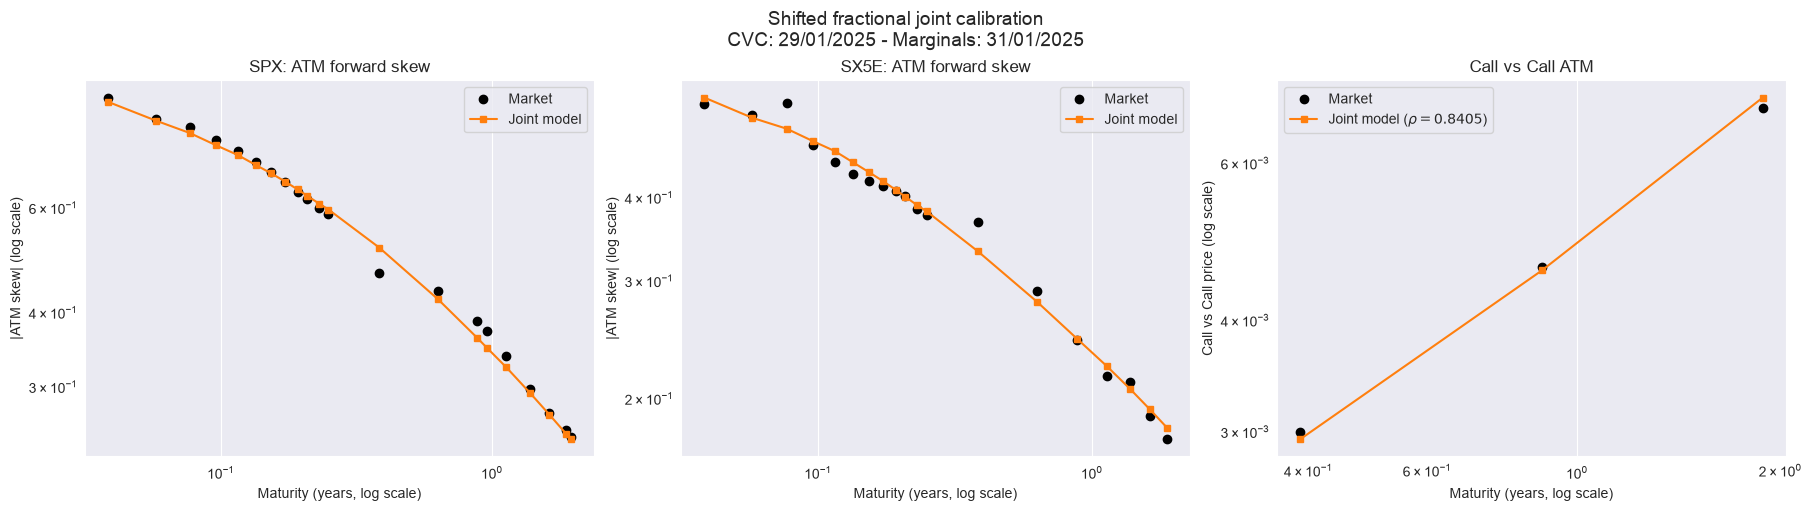

Plotted from: in-memory calibration result.


In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


# Saved checkpoint of the completed 29/01/2025 shifted/shifted calibration.
# It lets this plot run after a kernel restart without rerunning the optimizer.
completed_key = ('20250129', 'shifted_fractional')
checkpoint = {
    'parameters': np.array([
        0.127229, 0.759301, -0.999,
        0.068858, 0.411069, -0.999, 0.840545,
    ]),
    'spx_maturities': np.array([
        0.03835616, 0.05753425, 0.07671233, 0.09589041,
        0.11506849, 0.13424658, 0.15342466, 0.17260274,
        0.19178082, 0.20821918, 0.23013699, 0.24931507,
        0.38356164, 0.63287671, 0.88219178, 0.95890411,
        1.13150685, 1.37808219, 1.63013699, 1.87945205,
        1.95616438,
    ]),
    'spx_market': np.array([
        -0.91911604, -0.84678326, -0.82153013, -0.77837329,
        -0.74638690, -0.71518074, -0.68956155, -0.66194802,
        -0.63819891, -0.61989638, -0.60021252, -0.58541163,
        -0.46551452, -0.43491061, -0.38640042, -0.37248061,
        -0.33813766, -0.29774051, -0.27127939, -0.25395606,
        -0.24741028,
    ]),
    'spx_model': np.array([
        -0.90351074, -0.84040412, -0.80110926, -0.76399580,
        -0.73604917, -0.70802868, -0.68501088, -0.66381428,
        -0.64380819, -0.62814328, -0.60955249, -0.59574142,
        -0.51418467, -0.42078196, -0.36256490, -0.34875936,
        -0.32322957, -0.29335709, -0.26928698, -0.24999884,
        -0.24486031,
    ]),
    'sx5e_maturities': np.array([
        0.03835616, 0.05753425, 0.07671233, 0.09589041,
        0.11506849, 0.13424658, 0.15342466, 0.17260274,
        0.19178082, 0.20821918, 0.23013699, 0.24931507,
        0.38356164, 0.63287671, 0.88219178, 1.13150685,
        1.38082192, 1.63013699, 1.87945205,
    ]),
    'sx5e_market': np.array([
        -0.55206120, -0.53079336, -0.55303412, -0.47938645,
        -0.45251723, -0.43348146, -0.42333343, -0.41570367,
        -0.40924912, -0.40246070, -0.38438723, -0.37643515,
        -0.36742242, -0.28964985, -0.24425514, -0.21606894,
        -0.21175575, -0.18859267, -0.17381187,
    ]),
    'sx5e_model': np.array([
        -0.56445122, -0.52622192, -0.50696824, -0.48549580,
        -0.46926290, -0.45129282, -0.43636115, -0.42309609,
        -0.41071462, -0.40094099, -0.38935641, -0.38114248,
        -0.33214165, -0.27878003, -0.24583354, -0.22379713,
        -0.20662398, -0.19260368, -0.18095157,
    ]),
    'cvc_maturities': np.array([0.38904110, 0.88767123, 1.88493151]),
    'cvc_market': np.array([0.00299918, 0.00459384, 0.00691484]),
    'cvc_model': np.array([0.00294283, 0.00455024, 0.00710723]),
}

results_in_memory = globals().get('joint_calibration_results', {})
if completed_key in results_in_memory:
    completed_result = results_in_memory[completed_key]
    parameters = completed_result['parameters']
    model = completed_result['validation_model']
    spx_model = np.asarray(model['spx_skews'])
    sx5e_model = np.asarray(model['sx5e_skews'])
    cvc_model = np.asarray(model['cvc_prices'])
    result_source = 'in-memory calibration result'
else:
    parameters = checkpoint['parameters']
    spx_model = checkpoint['spx_model']
    sx5e_model = checkpoint['sx5e_model']
    cvc_model = checkpoint['cvc_model']
    result_source = 'saved calibration checkpoint'

rho_value = float(parameters[-1])
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
marginal_panels = (
    (
        axes[0], 'SPX', checkpoint['spx_maturities'],
        checkpoint['spx_market'], spx_model,
    ),
    (
        axes[1], 'SX5E', checkpoint['sx5e_maturities'],
        checkpoint['sx5e_market'], sx5e_model,
    ),
)
for axis, asset_label, maturities, market_values, model_values in marginal_panels:
    axis.loglog(
        maturities, np.abs(market_values),
        'o', color='black', label='Market',
    )
    axis.loglog(
        maturities, np.abs(model_values),
        '-s', markersize=4, color='tab:orange', label='Joint model',
    )
    axis.set_title(f'{asset_label}: ATM forward skew')
    axis.set_xlabel('Maturity (years, log scale)')
    axis.set_ylabel('|ATM skew| (log scale)')
    axis.grid(True)
    axis.legend()

axes[2].loglog(
    checkpoint['cvc_maturities'], checkpoint['cvc_market'],
    'o', color='black', label='Market',
)
axes[2].loglog(
    checkpoint['cvc_maturities'], cvc_model,
    '-s', markersize=4, color='tab:orange',
    label=rf'Joint model ($\rho={rho_value:.4f}$)',
)
axes[2].set_title('Call vs Call ATM')
axes[2].set_xlabel('Maturity (years, log scale)')
axes[2].set_ylabel('Call vs Call price (log scale)')
axes[2].grid(True)
axes[2].legend()

fig.suptitle(
    'Shifted fractional joint calibration\n'
    'CVC: 29/01/2025 - Marginals: 31/01/2025',
    fontsize=14,
)
project_root = next((
    root for root in [Path.cwd(), *Path.cwd().parents]
    if (root / 'src' / 'vss').is_dir()
), Path.cwd())
target_directory = (
    project_root
    / 'Plots vss_joint_calibration_CACIB_SP500_SX5E_skew_vars_cvc_2y'
    / 'Individual joint calibrations'
)
target_directory.mkdir(parents=True, exist_ok=True)
fig.savefig(
    target_directory / '20250129_shifted_fractional.png',
    dpi=200,
    bbox_inches='tight',
)
plt.show()
print(f'Plotted from: {result_source}.')

## 29/01/2025 — two exponentials / two exponentials

In [12]:
key = ('20250129', 'two_exp')
result = calibrate_joint_model(*key)
joint_calibration_results[key] = result
display_joint_calibration(result)

20250129 / Two exponentials: success=True, nfev=11, elapsed=386.1s
`ftol` termination condition is satisfied.


,parameter,initial,calibrated,change,lower_bound,upper_bound
0,kappa_1_SPX,0.657433,0.726646,6.921291e-02,0.010,3.000
1,kappa_2_SPX,24.886429,22.670871,-2.215557e+00,3.000,50.000
2,a_1_SPX,0.455708,0.454689,-1.018539e-03,0.000,1.000
3,nu_SPX,2.346555,2.301170,-4.538466e-02,0.010,10.000
4,c_SPX,-0.999000,-0.999000,1.110223e-16,-0.999,-0.001
5,kappa_1_SX5E,1.321061,1.236834,-8.422771e-02,0.010,3.000
6,kappa_2_SX5E,32.388074,30.208007,-2.180067e+00,3.000,50.000
7,a_1_SX5E,0.496878,0.486652,-1.022612e-02,0.000,1.000
8,nu_SX5E,1.437123,1.418845,-1.827792e-02,0.010,10.000
9,c_SX5E,-0.993500,-0.999000,-5.500210e-03,-0.999,-0.001


,stage,block,log_RMSE,maximum_absolute_log_error
0,initial,SPX ATM skew,0.025965,0.094702
1,initial,SX5E ATM skew,0.035639,0.089694
2,initial,CVC,0.033513,0.043640
3,calibration,SPX ATM skew,0.029477,0.086791
4,calibration,SX5E ATM skew,0.035930,0.088451
5,calibration,CVC,0.022452,0.030969
6,validation,SPX ATM skew,0.029477,0.086791
7,validation,SX5E ATM skew,0.035930,0.088451
8,validation,CVC,0.022452,0.030969


## 29/07/2025 — shifted fractional / shifted fractional

In [13]:
key = ('20250729', 'shifted_fractional')
result = calibrate_joint_model(*key)
joint_calibration_results[key] = result
display_joint_calibration(result)

20250729 / Shifted fractional: success=True, nfev=5, elapsed=152.8s
`ftol` termination condition is satisfied.


,parameter,initial,calibrated,change,lower_bound,upper_bound
0,H_SPX,0.104502,0.084489,-2.001281e-02,-0.490,0.500
1,nu_SPX,0.922617,0.889213,-3.340336e-02,0.010,0.950
2,c_SPX,-0.999000,-0.999000,1.110223e-16,-0.999,-0.001
3,H_SX5E,-0.116221,-0.111841,4.380398e-03,-0.490,0.500
4,nu_SX5E,0.493238,0.494420,1.181501e-03,0.010,0.900
5,c_SX5E,-0.999000,-0.999000,1.110223e-16,-0.999,-0.001
6,rho,0.897543,0.891250,-6.292596e-03,-0.999,0.999


,stage,block,log_RMSE,maximum_absolute_log_error
0,initial,SPX ATM skew,0.035699,0.088478
1,initial,SX5E ATM skew,0.037076,0.087945
2,initial,CVC,0.041201,0.054630
3,calibration,SPX ATM skew,0.037504,0.079519
4,calibration,SX5E ATM skew,0.037217,0.089123
5,calibration,CVC,0.033602,0.042658
6,validation,SPX ATM skew,0.037504,0.079519
7,validation,SX5E ATM skew,0.037217,0.089123
8,validation,CVC,0.033602,0.042658


## 29/07/2025 — two exponentials / two exponentials

In [14]:
key = ('20250729', 'two_exp')
result = calibrate_joint_model(*key)
joint_calibration_results[key] = result
display_joint_calibration(result)

20250729 / Two exponentials: success=True, nfev=33, elapsed=1146.3s
`ftol` termination condition is satisfied.


,parameter,initial,calibrated,change,lower_bound,upper_bound
0,kappa_1_SPX,0.454068,0.754112,3.000439e-01,0.010,3.000
1,kappa_2_SPX,19.961455,23.246465,3.285010e+00,3.000,50.000
2,a_1_SPX,0.376057,0.421673,4.561633e-02,0.000,1.000
3,nu_SPX,2.936900,2.950826,1.392584e-02,0.010,10.000
4,c_SPX,-0.999000,-0.999000,-2.600000e-07,-0.999,-0.001
5,kappa_1_SX5E,0.077937,0.402329,3.243920e-01,0.010,3.000
6,kappa_2_SX5E,20.272142,21.164103,8.919611e-01,3.000,50.000
7,a_1_SX5E,0.263631,0.208024,-5.560691e-02,0.000,1.000
8,nu_SX5E,3.106738,2.509877,-5.968613e-01,0.010,10.000
9,c_SX5E,-0.748681,-0.926555,-1.778747e-01,-0.999,-0.001


,stage,block,log_RMSE,maximum_absolute_log_error
0,initial,SPX ATM skew,0.027317,0.078641
1,initial,SX5E ATM skew,0.019783,0.055599
2,initial,CVC,0.065858,0.088083
3,calibration,SPX ATM skew,0.030167,0.079689
4,calibration,SX5E ATM skew,0.020770,0.056931
5,calibration,CVC,0.025839,0.031818
6,validation,SPX ATM skew,0.030167,0.079689
7,validation,SX5E ATM skew,0.020770,0.056931
8,validation,CVC,0.025839,0.031818


# Full calibration results

The two figures below contain only market observations and results from the joint calibrations. No curve from the cascade calibration is plotted.

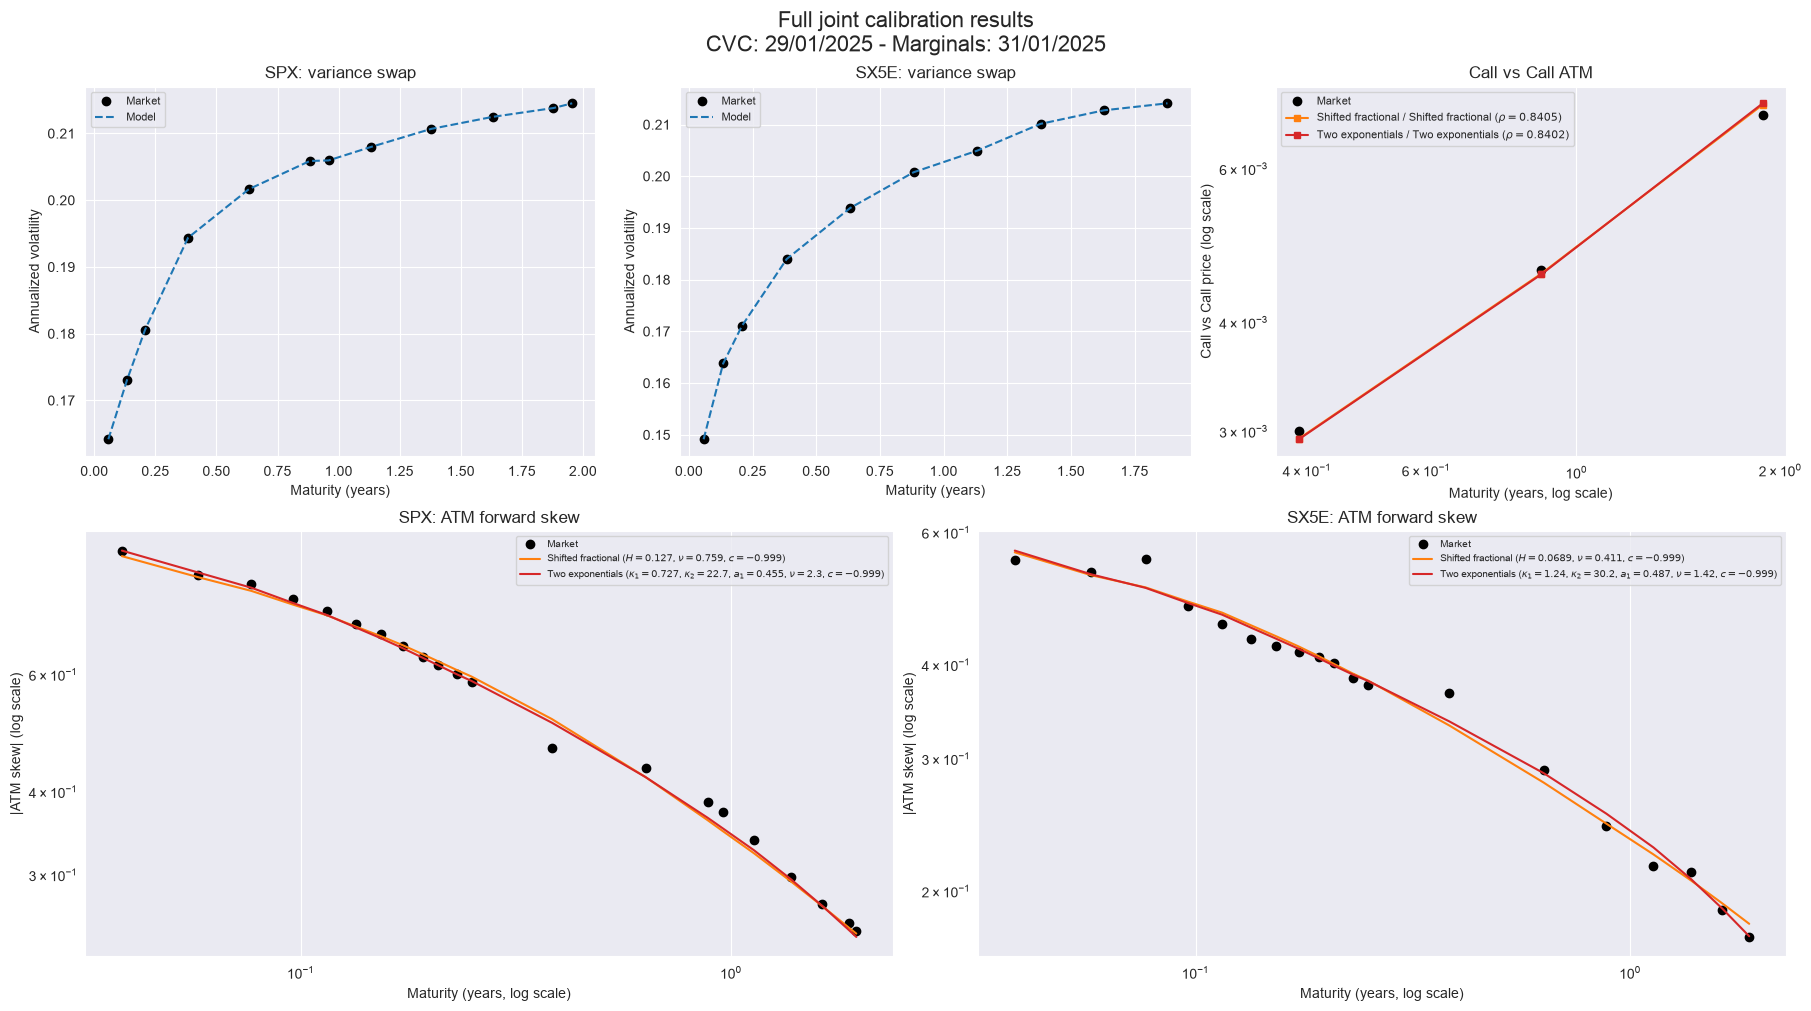

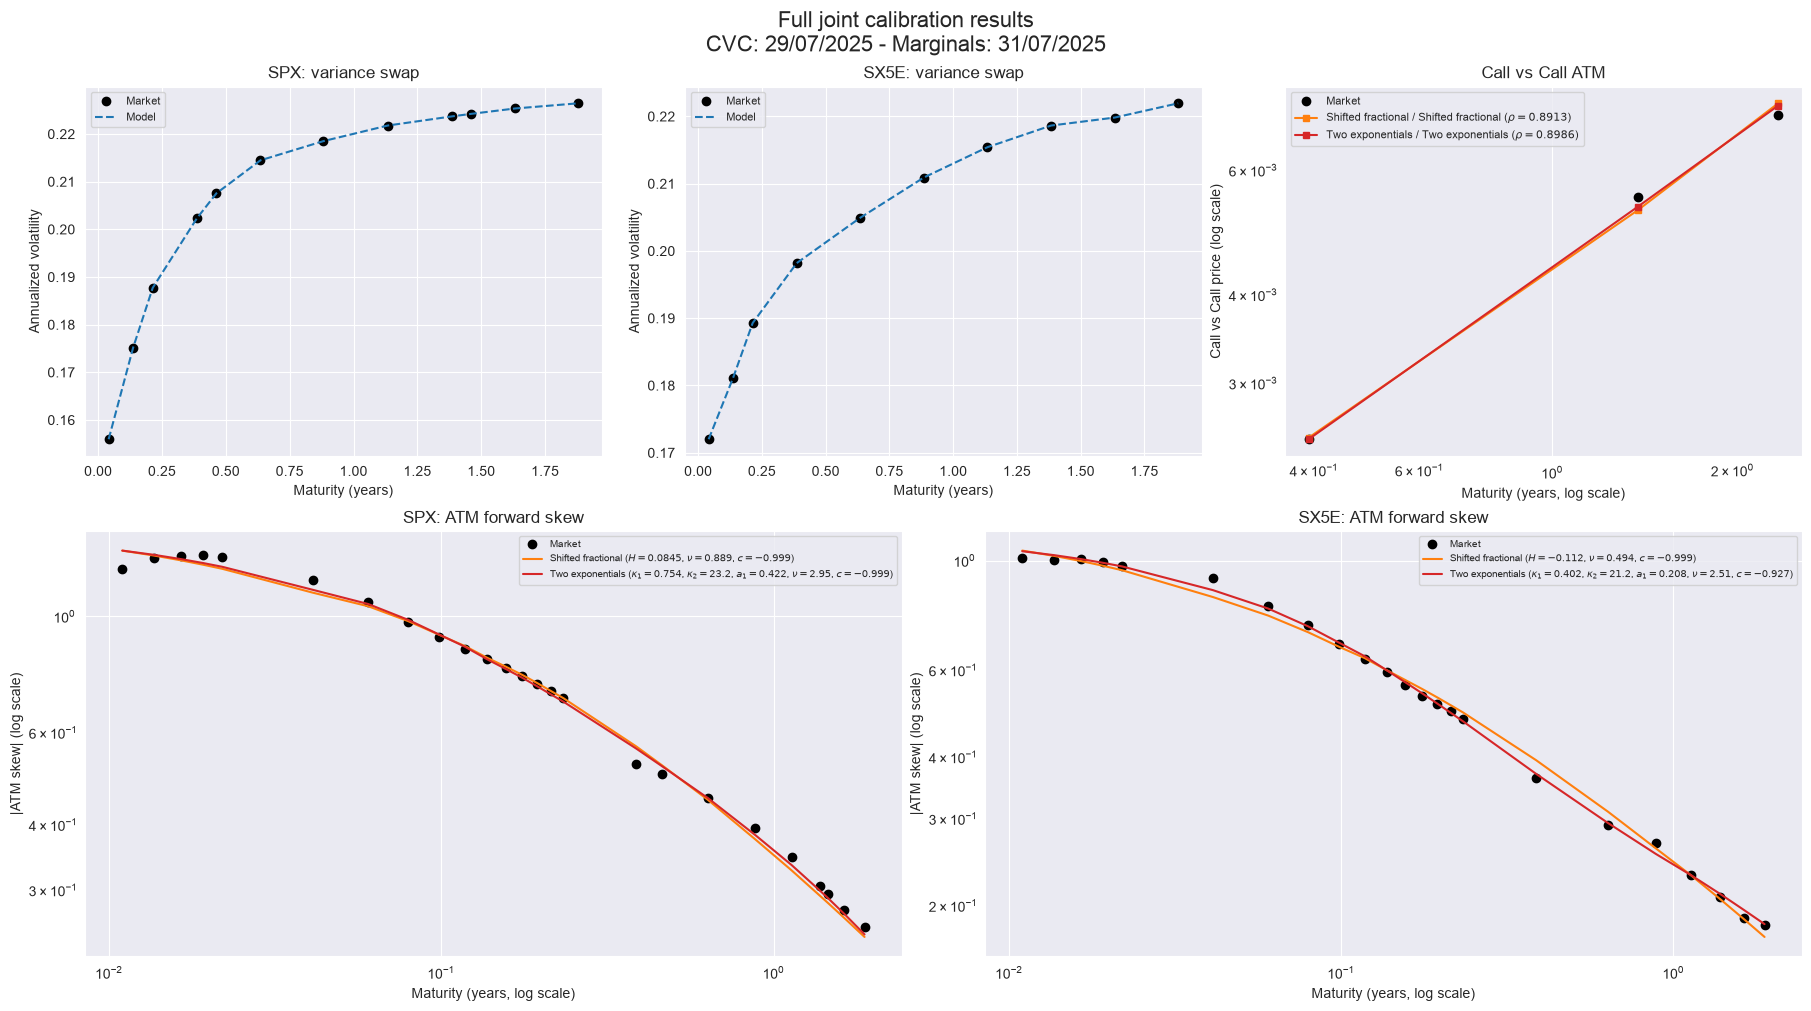

In [15]:
PARAMETER_TEX = {
    'H': r'H', 'nu': r'\nu', 'c': r'c',
    'kappa_1': r'\kappa_1', 'kappa_2': r'\kappa_2',
    'a_1': r'a_1',
}


def date_label(date):
    return f'{date[6:8]}/{date[4:6]}/{date[:4]}'


def marginal_parameters_from_result(result, asset_label):
    """Return display names and calibrated marginal parameters."""

    spx, sx5e, _ = split_joint_parameters(
        result['kernel_key'], result['parameters']
    )
    values = spx if asset_label == 'SPX' else sx5e
    if result['kernel_key'] == 'shifted_fractional':
        names = ('H', 'nu', 'c')
    else:
        names = ('kappa_1', 'kappa_2', 'a_1', 'nu', 'c')
    return names, values


def marginal_result_label(result, asset_label):
    names, values = marginal_parameters_from_result(result, asset_label)
    parameters = ', '.join(
        f'${PARAMETER_TEX[name]}={value:.3g}$'
        for name, value in zip(names, values)
    )
    return f'{KERNEL_LABELS[result["kernel_key"]]} ({parameters})'


def plot_variance_swap(axis, dataset, asset_label):
    comparison = g0_results[dataset]['comparison']
    axis.plot(
        comparison['maturity'], comparison['variance_swap_quote'],
        'o', color='black', label='Market',
    )
    axis.plot(
        comparison['maturity'],
        comparison['reconstructed_variance_swap_quote'],
        '--', color='tab:blue', label='Model',
    )
    axis.set_title(f'{asset_label}: variance swap')
    axis.set_xlabel('Maturity (years)')
    axis.set_ylabel('Annualized volatility')
    axis.grid(True)
    axis.legend(fontsize=8)


def plot_joint_atm_skew(axis, cvc_date, asset_label):
    marginal_date = CVC_TO_MARGINAL_DATE[cvc_date]
    dataset = f'{asset_label}_{marginal_date}'
    axis.loglog(
        market_skew_maturities[dataset], np.abs(market_skews[dataset]),
        'o', color='black', label='Market',
    )
    model_key = 'spx_skews' if asset_label == 'SPX' else 'sx5e_skews'
    for kernel_key in ('shifted_fractional', 'two_exp'):
        result = joint_calibration_results[(cvc_date, kernel_key)]
        axis.loglog(
            market_skew_maturities[dataset],
            np.abs(result['validation_model'][model_key]),
            '-', color=KERNEL_COLORS[kernel_key],
            label=marginal_result_label(result, asset_label),
        )
    axis.set_title(f'{asset_label}: ATM forward skew')
    axis.set_xlabel('Maturity (years, log scale)')
    axis.set_ylabel('|ATM skew| (log scale)')
    axis.grid(True)
    axis.legend(fontsize=7)


def plot_joint_cvc(axis, cvc_date):
    market = cvc_market_data[cvc_date]
    axis.loglog(
        market['maturity'], market['call_vs_call_quote'],
        'o', color='black', label='Market',
    )
    for kernel_key in ('shifted_fractional', 'two_exp'):
        result = joint_calibration_results[(cvc_date, kernel_key)]
        _, _, rho_value = split_joint_parameters(
            kernel_key, result['parameters']
        )
        axis.loglog(
            market['maturity'], result['validation_model']['cvc_prices'],
            '-s', markersize=4, color=KERNEL_COLORS[kernel_key],
            label=(
                f'{KERNEL_LABELS[kernel_key]} / {KERNEL_LABELS[kernel_key]} '
                rf'($\rho={rho_value:.4f}$)'
            ),
        )
    axis.set_title('Call vs Call ATM')
    axis.set_xlabel('Maturity (years, log scale)')
    axis.set_ylabel('Call vs Call price (log scale)')
    axis.grid(True)
    axis.legend(fontsize=8)


def plot_full_joint_calibration_result(cvc_date):
    """Build and save the five-panel joint-calibration result."""

    required = [
        (cvc_date, 'shifted_fractional'),
        (cvc_date, 'two_exp'),
    ]
    missing = [key for key in required if key not in joint_calibration_results]
    if missing:
        raise RuntimeError(f'Run the missing joint calibrations first: {missing}')

    marginal_date = CVC_TO_MARGINAL_DATE[cvc_date]
    fig = plt.figure(figsize=(18, 10), constrained_layout=True)
    grid = fig.add_gridspec(2, 6, height_ratios=(1.0, 1.15))
    axes = {
        'spx_variance_swap': fig.add_subplot(grid[0, 0:2]),
        'sx5e_variance_swap': fig.add_subplot(grid[0, 2:4]),
        'cvc': fig.add_subplot(grid[0, 4:6]),
        'spx_atm_skew': fig.add_subplot(grid[1, 0:3]),
        'sx5e_atm_skew': fig.add_subplot(grid[1, 3:6]),
    }
    plot_variance_swap(
        axes['spx_variance_swap'], f'SPX_{marginal_date}', 'SPX'
    )
    plot_variance_swap(
        axes['sx5e_variance_swap'], f'SX5E_{marginal_date}', 'SX5E'
    )
    plot_joint_cvc(axes['cvc'], cvc_date)
    plot_joint_atm_skew(axes['spx_atm_skew'], cvc_date, 'SPX')
    plot_joint_atm_skew(axes['sx5e_atm_skew'], cvc_date, 'SX5E')
    fig.suptitle(
        'Full joint calibration results\n'
        f'CVC: {date_label(cvc_date)} - '
        f'Marginals: {date_label(marginal_date)}',
        fontsize=16,
    )
    fig.savefig(
        FULL_RESULTS_DIRECTORY / f'full_joint_calibration_{cvc_date}.png',
        dpi=200, bbox_inches='tight',
    )
    plt.show()
    return fig


full_joint_calibration_figures = {
    cvc_date: plot_full_joint_calibration_result(cvc_date)
    for cvc_date in CVC_DATES
}